In [6]:
import sys
from pathlib import Path


project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))
print("Using project root:", project_root)

Using project root: /home/mbz/Documents/PhD/SCD41_DATA


In [21]:
from src.config import PipelineConfig
from src.pipeline import SensorPipeline
from src.logging_utils import setup_logging
config = PipelineConfig.from_yaml(Path("../config/sensors.yaml"))
print(f"Loaded {len(config.sensors)} sensors:")
for s in config.sensors:
    print(f"  - {s.name} ({s.sensor_type}, altitude: {s.altitude_m}m)")
setup_logging(config.log_dir, log_name="notebook_run")

pipeline = SensorPipeline(config, force=False)

2025-12-09 19:12:43,512 - root - INFO - Logging initialized. Log file: /home/mbz/Documents/PhD/SCD41_DATA/output/logs/notebook_run_20251209_191243.log


Loaded 5 sensors:
  - CO2_SCT1_2M (scd41, altitude: 2m)
  - CO2_30M_A (scd41, altitude: 30m)
  - CO2_30M_B (scd41, altitude: 30m)
  - CO2_30M_C (scd41, altitude: 30m)
  - LGR_30M (lgr_csv, altitude: 30m)


In [22]:
pipeline.run_all(year=2024, month=9)

2025-12-09 19:12:44,045 - src.pipeline - INFO - Starting pipeline for all sensors
2025-12-09 19:12:44,046 - src.pipeline - INFO - ============================================================
2025-12-09 19:12:44,047 - src.pipeline - INFO - Processing sensor: CO2_SCT1_2M
2025-12-09 19:12:44,047 - src.pipeline - INFO - ============================================================
2025-12-09 19:12:44,111 - src.pipeline - INFO - Found 19 days ((2024, 9, 12) to (2024, 9, 30))
2025-12-09 19:12:44,113 - src.pipeline - INFO - Processed 0 days
2025-12-09 19:12:44,137 - src.pipeline - INFO - Exported 2678 rows → CO2_SCT1_2M_2024_09.parquet
2025-12-09 19:12:44,138 - src.pipeline - INFO - ✓ CO2_SCT1_2M complete

2025-12-09 19:12:44,143 - src.pipeline - INFO - ============================================================
2025-12-09 19:12:44,144 - src.pipeline - INFO - Processing sensor: CO2_30M_A
2025-12-09 19:12:44,144 - src.pipeline - INFO - ==========================================================

In [19]:
pipeline.run_all(year=2024, month=10)

2025-12-09 19:07:12,694 - src.pipeline - INFO - Starting pipeline for all sensors
2025-12-09 19:07:12,695 - src.pipeline - INFO - ============================================================
2025-12-09 19:07:12,695 - src.pipeline - INFO - Processing sensor: CO2_SCT1_2M
2025-12-09 19:07:12,696 - src.pipeline - INFO - ============================================================
2025-12-09 19:07:12,754 - src.pipeline - INFO - Found 31 days ((2024, 10, 1) to (2024, 10, 31))
2025-12-09 19:07:12,756 - src.pipeline - INFO - Processed 0 days
2025-12-09 19:07:12,781 - src.pipeline - INFO - Exported 4375 rows → CO2_SCT1_2M_2024_10.parquet
2025-12-09 19:07:12,781 - src.pipeline - INFO - ✓ CO2_SCT1_2M complete

2025-12-09 19:07:12,787 - src.pipeline - INFO - ============================================================
2025-12-09 19:07:12,787 - src.pipeline - INFO - Processing sensor: CO2_30M_A
2025-12-09 19:07:12,788 - src.pipeline - INFO - =========================================================

In [20]:
from src.visualization import TaylorDiagram

taylor = TaylorDiagram("plots/")

# Professional Taylor diagram
taylor.plot(
    reference_csv="output/LGR_30M_10min.csv",
    test_csvs={
        "CO2_30M_1": "output/CO2_30M_1_10min.csv",
        "CO2_30M_2": "output/CO2_30M_2_10min.csv",
        "CO2_30M_3": "output/CO2_30M_3_10min.csv"
    },
    reference_name="LGR",
    # marker_colors=['steelblue', 'coral', 'seagreen'],
    # marker_symbols=['o', 's', '^']
)

FileNotFoundError: [Errno 2] No such file or directory: 'output/LGR_30M_10min.csv'

Generating plots...
  - CO2_SCT1_2M: Uptime timeseries


2025-12-09 18:32:23,434 - UptimePlots - INFO - Saved: CO2_SCT1_2M_uptime_timeseries.png


  - CO2_SCT1_2M: Uptime heatmap


2025-12-09 18:32:23,884 - UptimePlots - INFO - Saved: CO2_SCT1_2M_uptime_heatmap.png


  - CO2_SCT1_2M: QC summary


2025-12-09 18:32:24,250 - QualityControlPlots - INFO - Saved: CO2_SCT1_2M_qc_summary.png


... (14 outputs left out)

  - CO2 timeseries comparison


2025-12-09 18:32:26,817 - ValidationPlots - INFO - Saved: co2_timeseries_comparison.png



✓ All plots saved to: /home/mbz/Documents/PhD/SCD41_DATA/output/plots


/home/mbz/Documents/PhD/SCD41_DATA/venv/lib/python3.12/site-packages/IPython/core/events.py:96: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  func(*args, **kwargs)


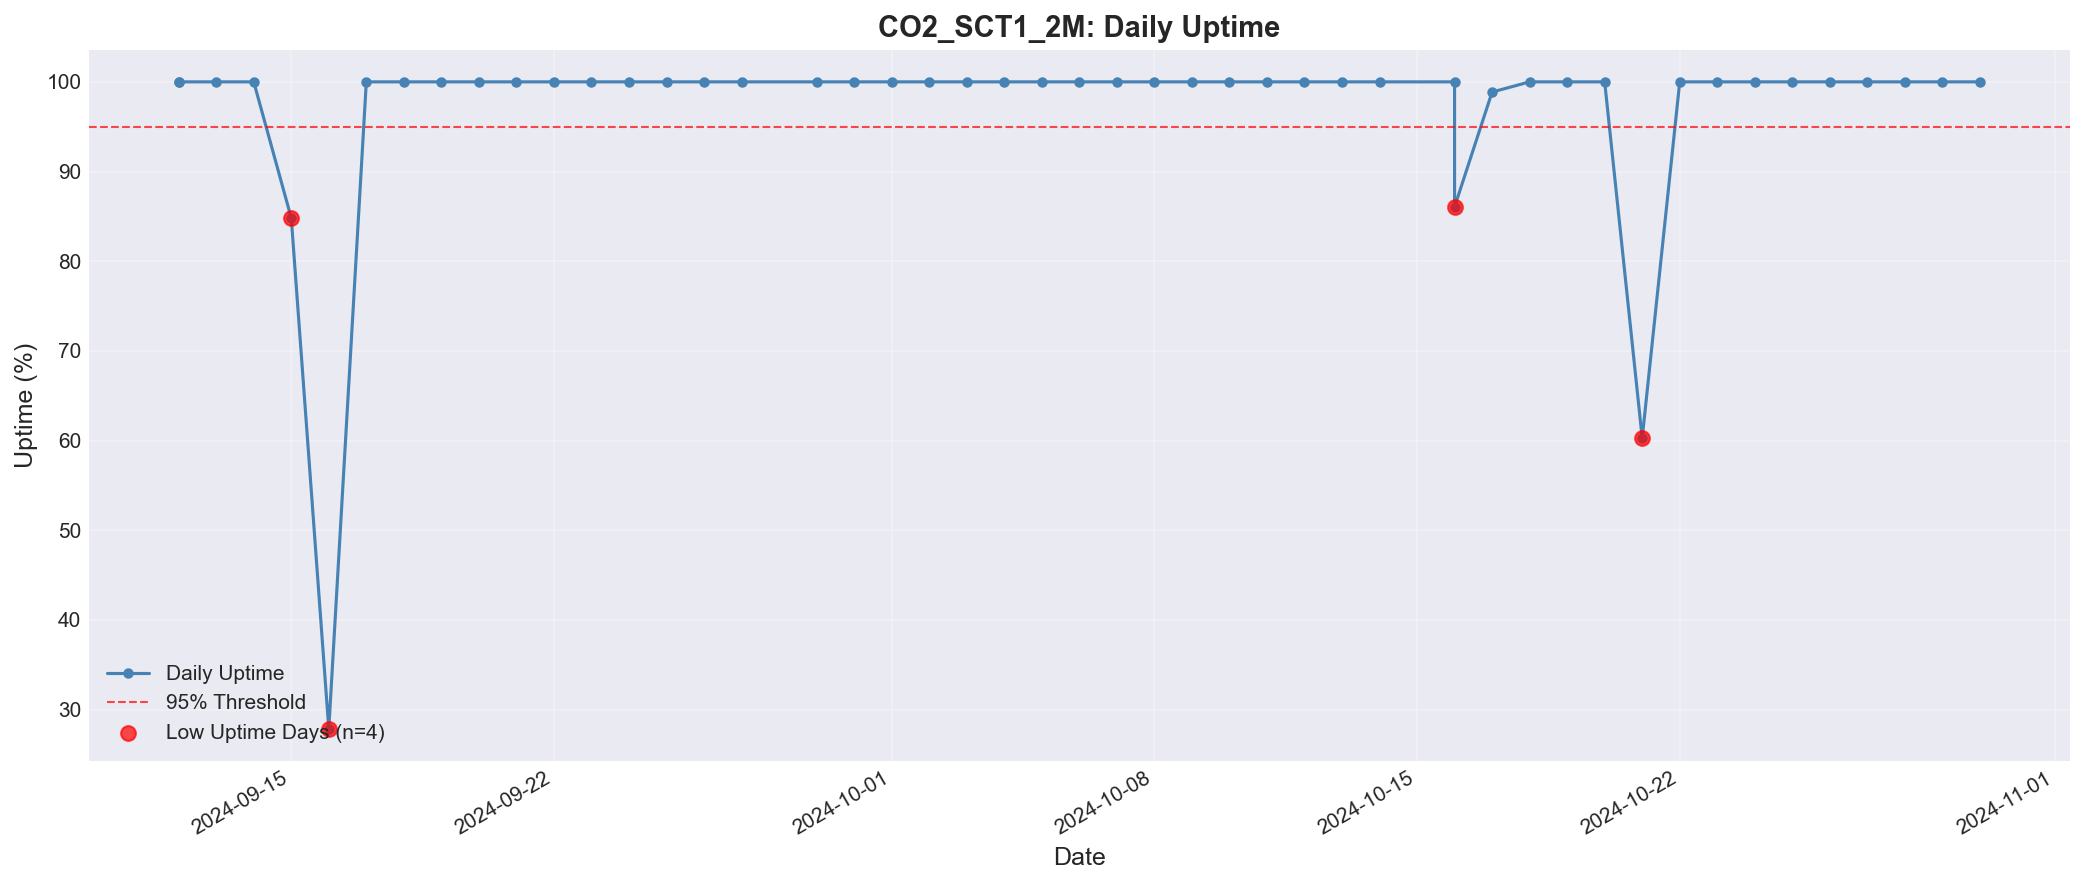

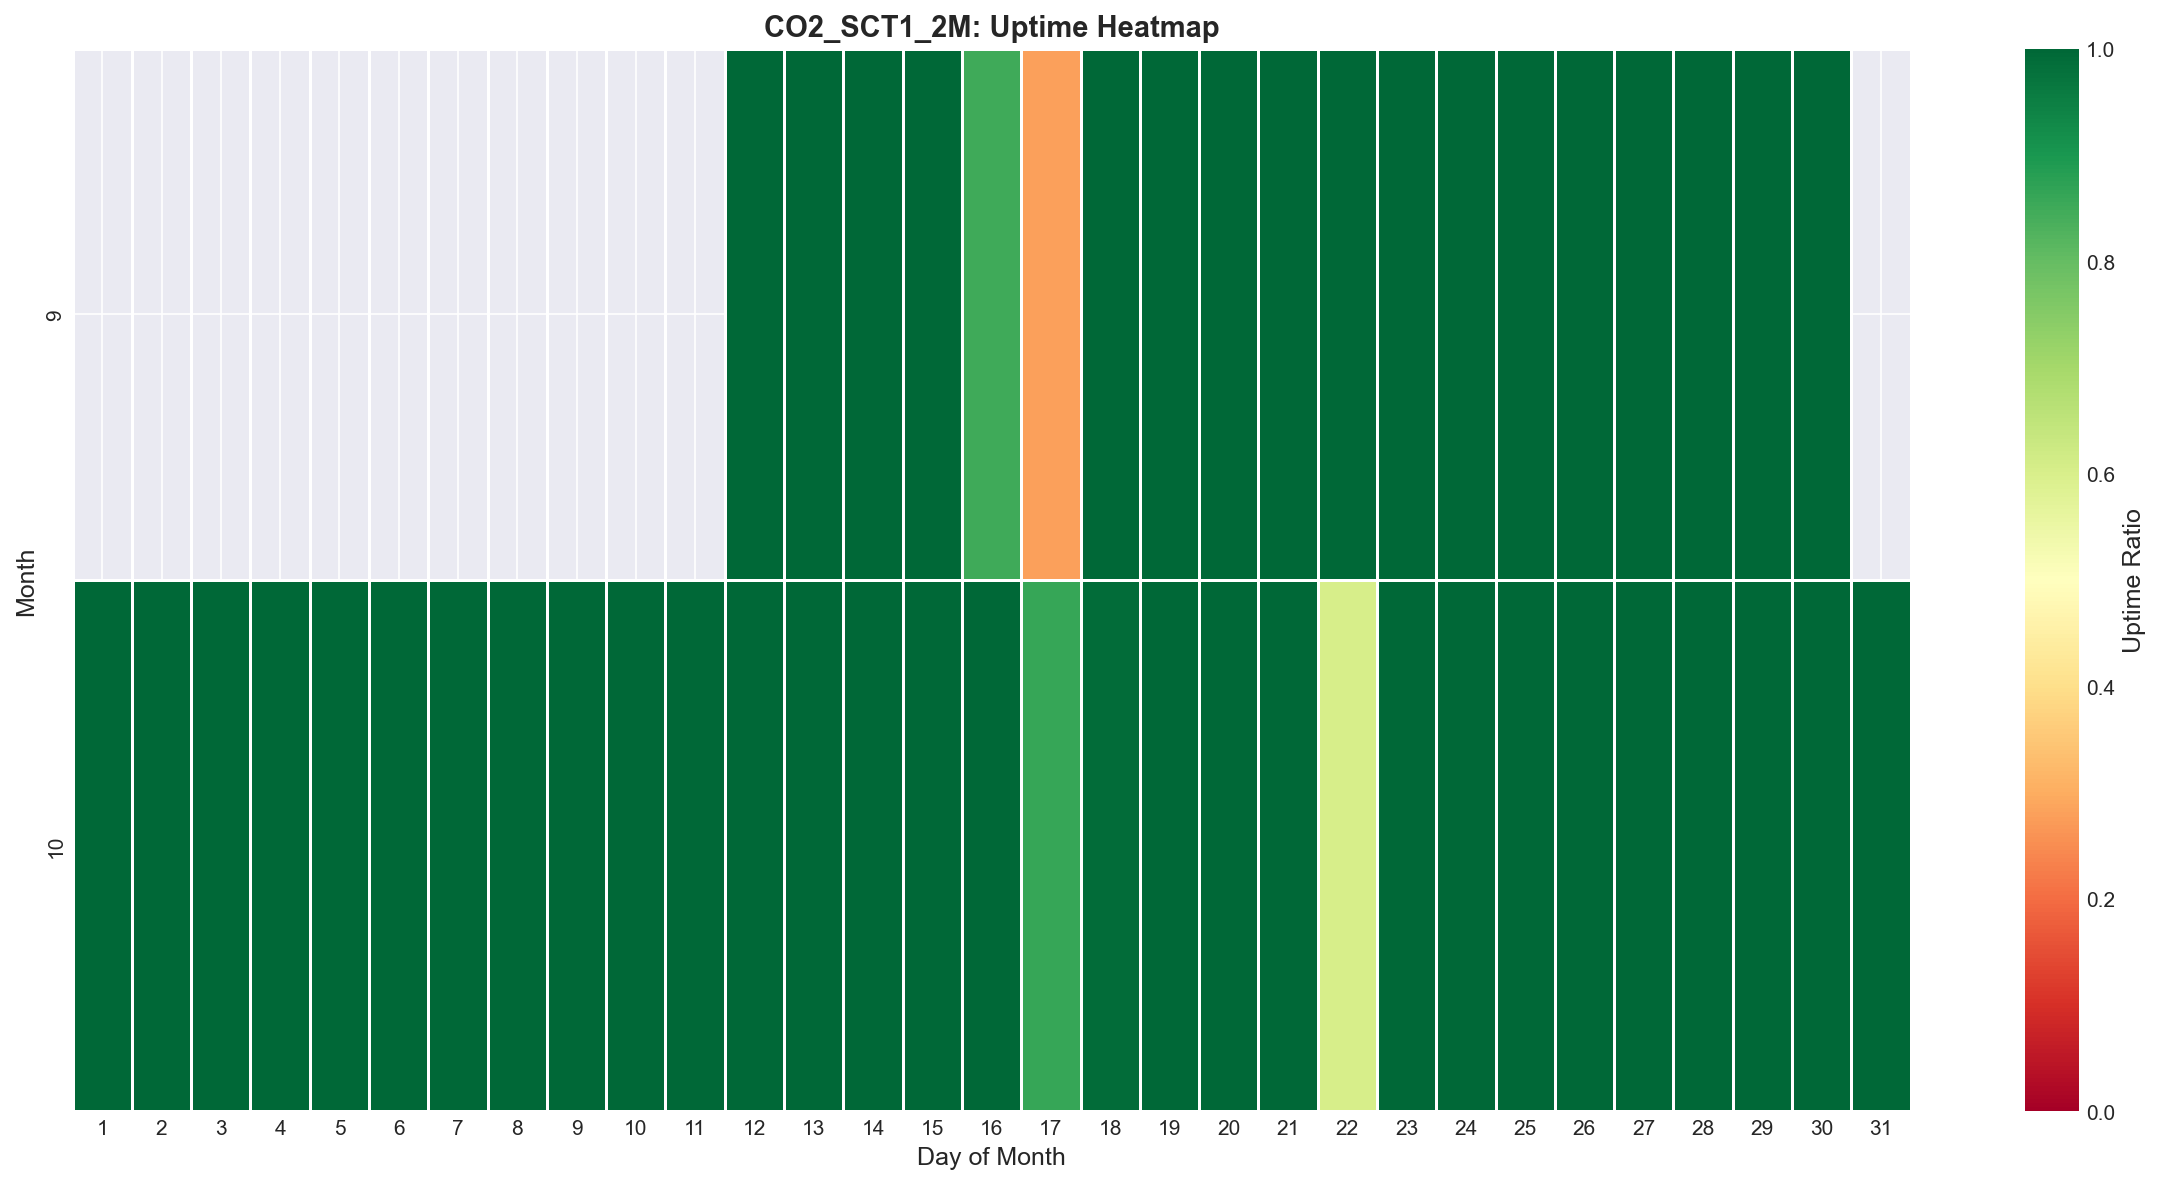

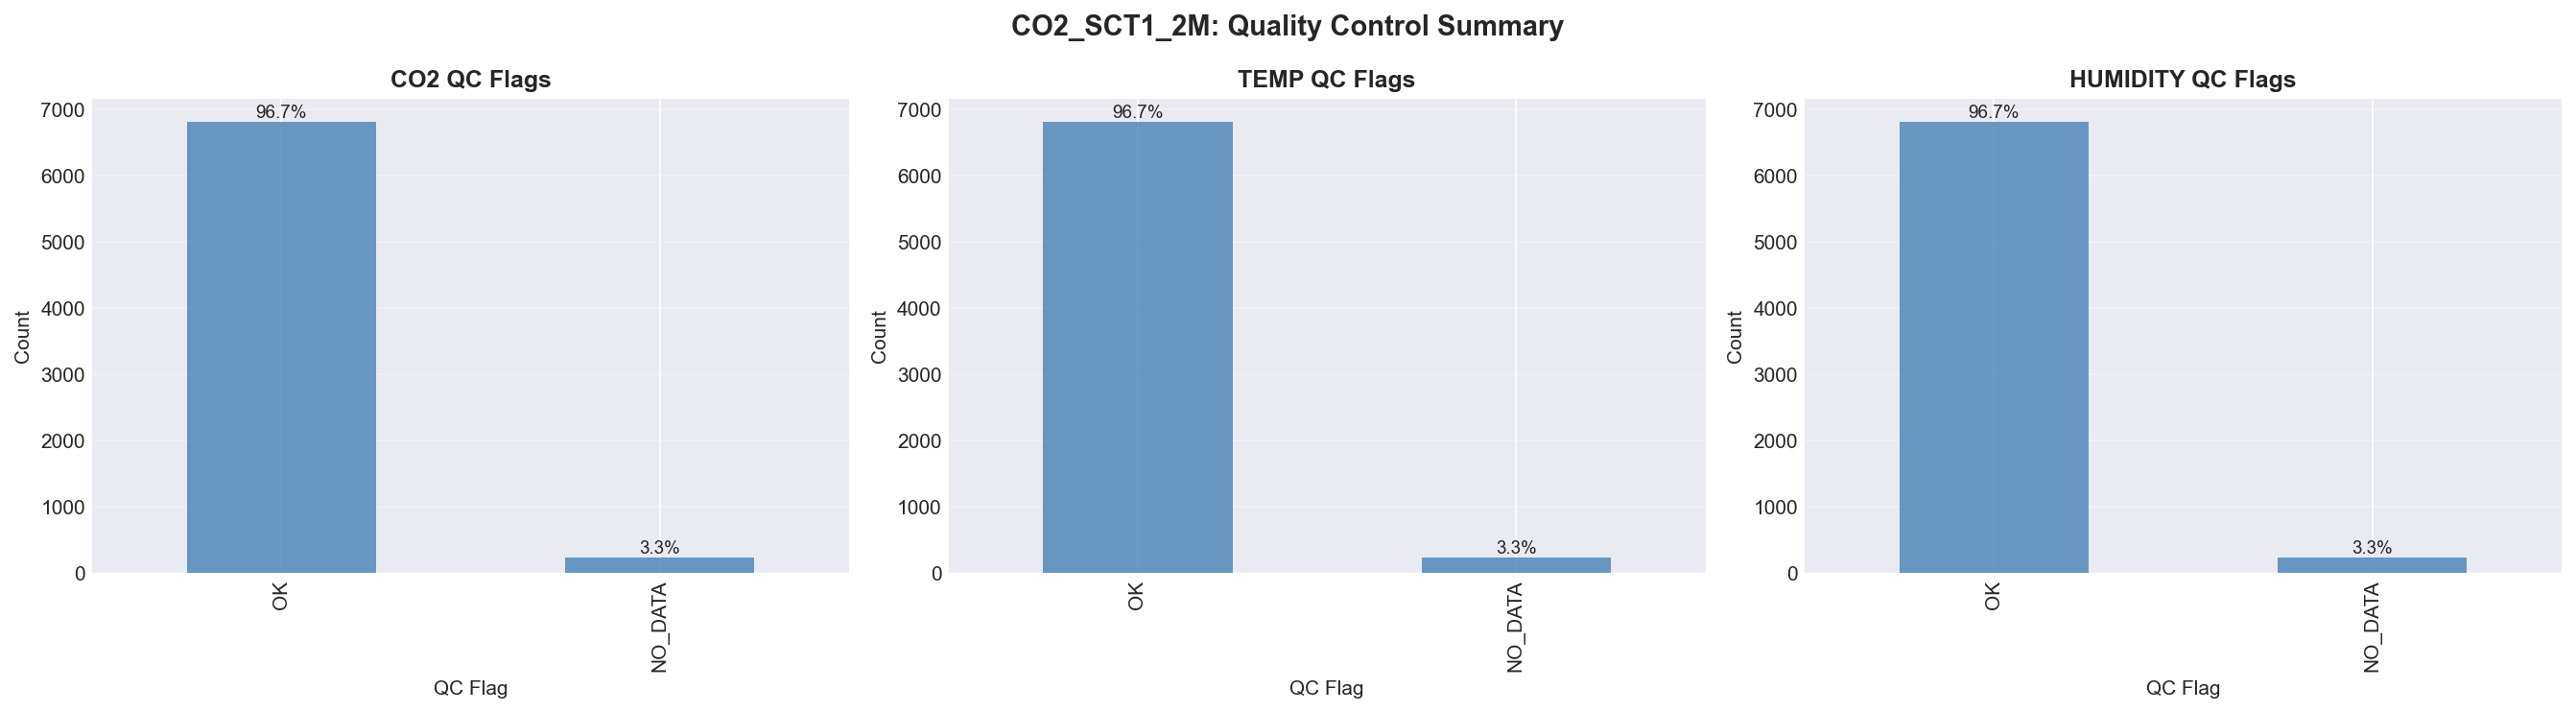

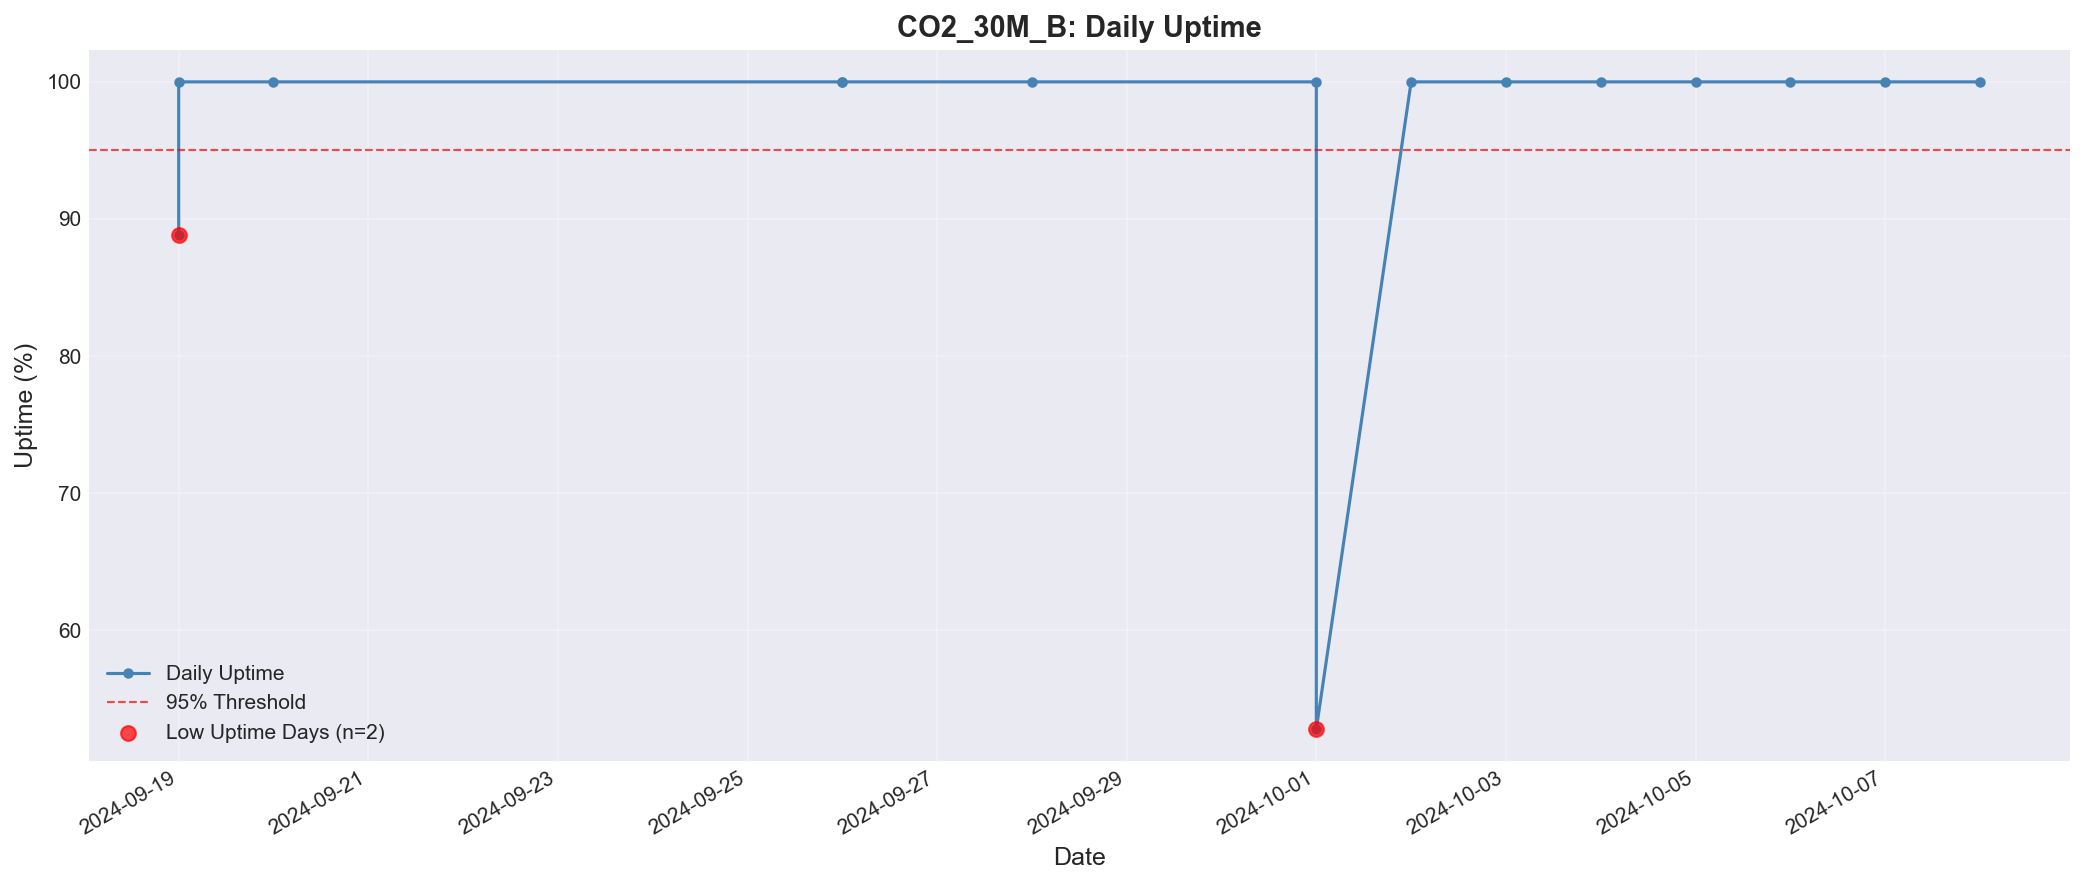

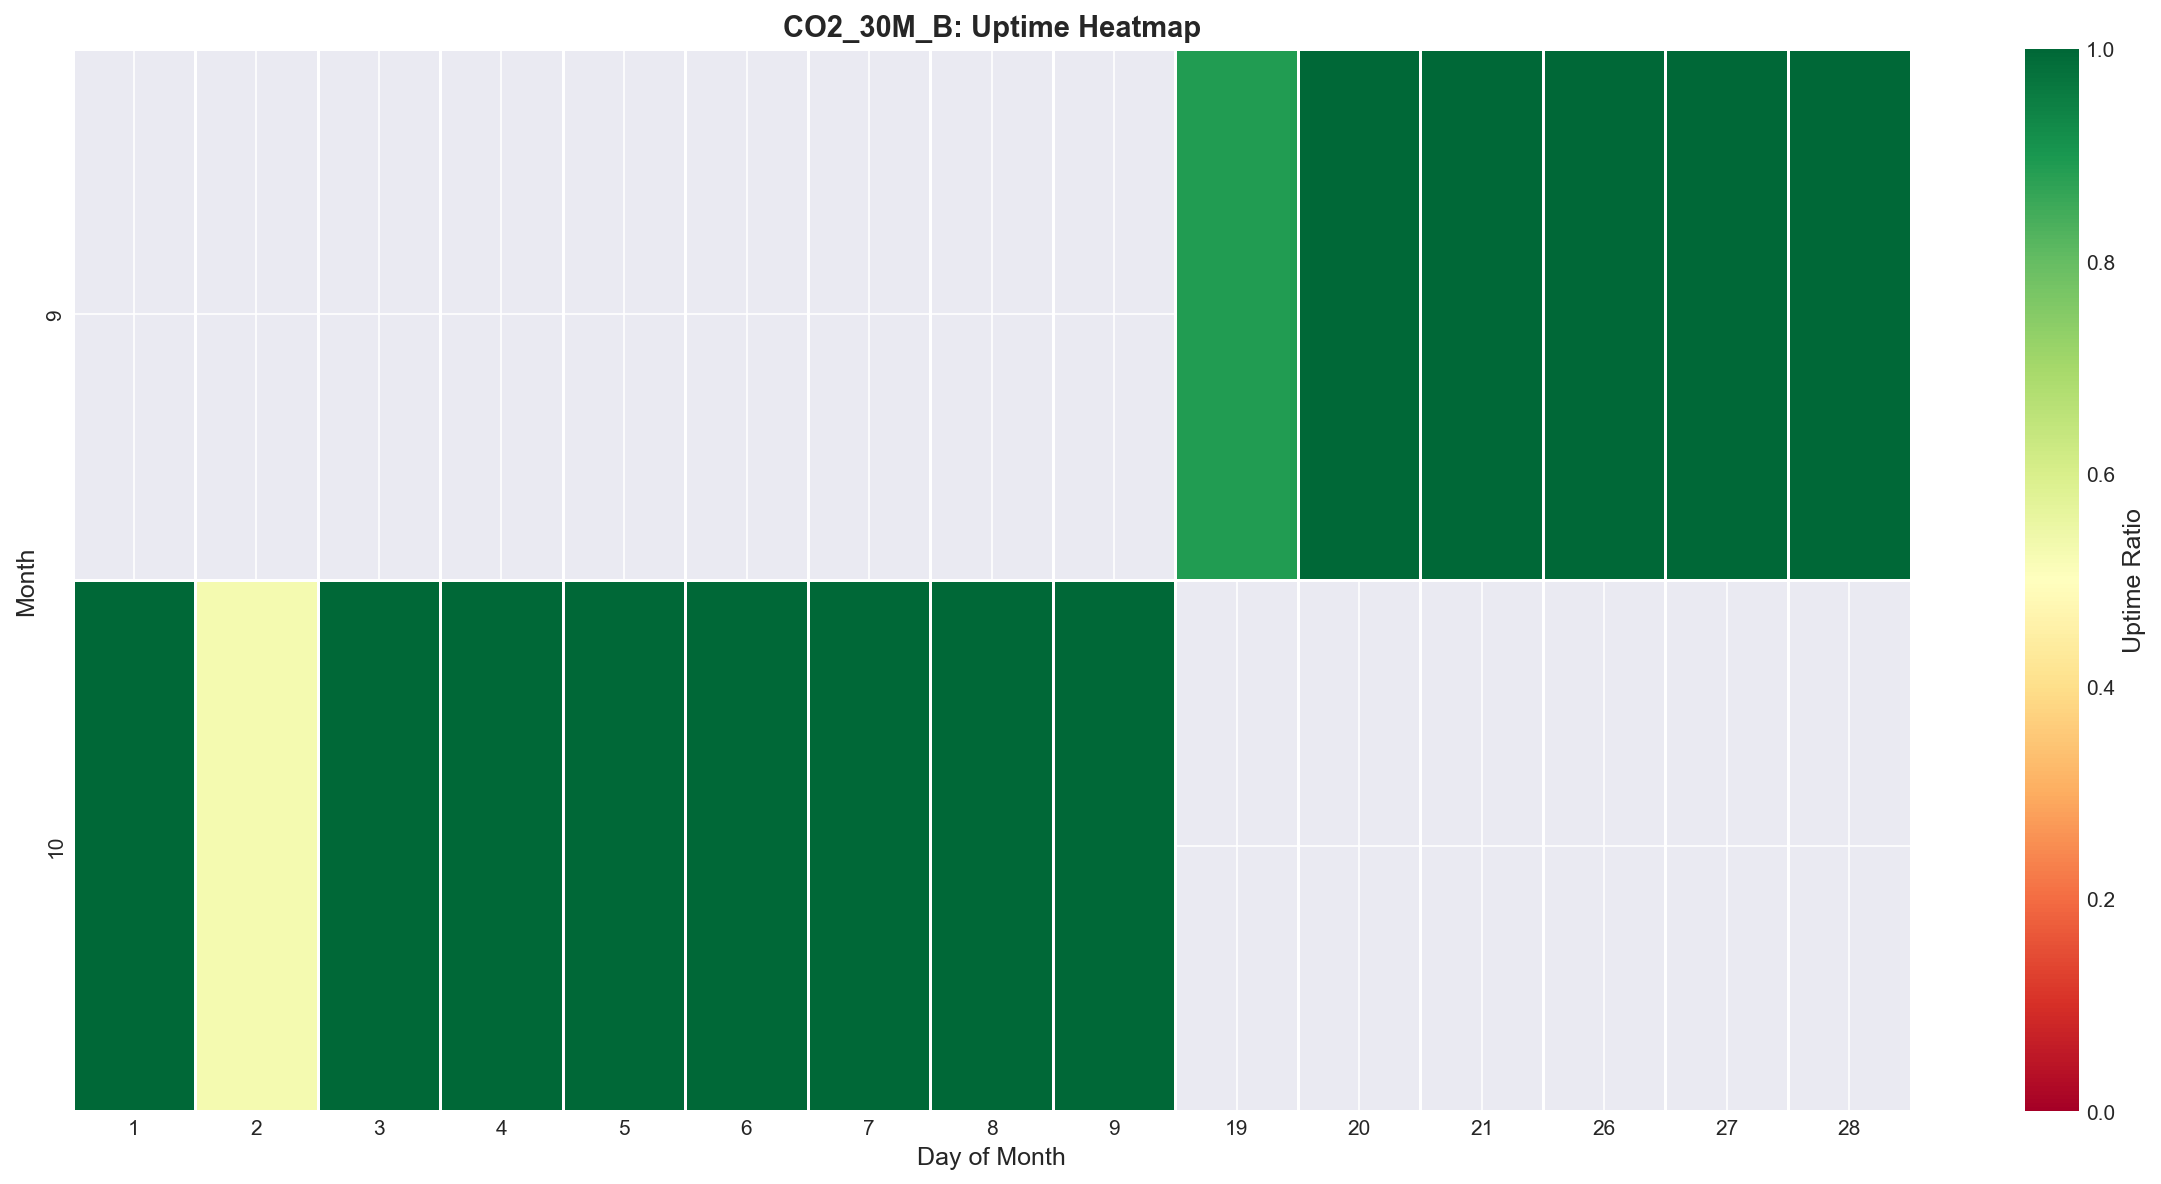

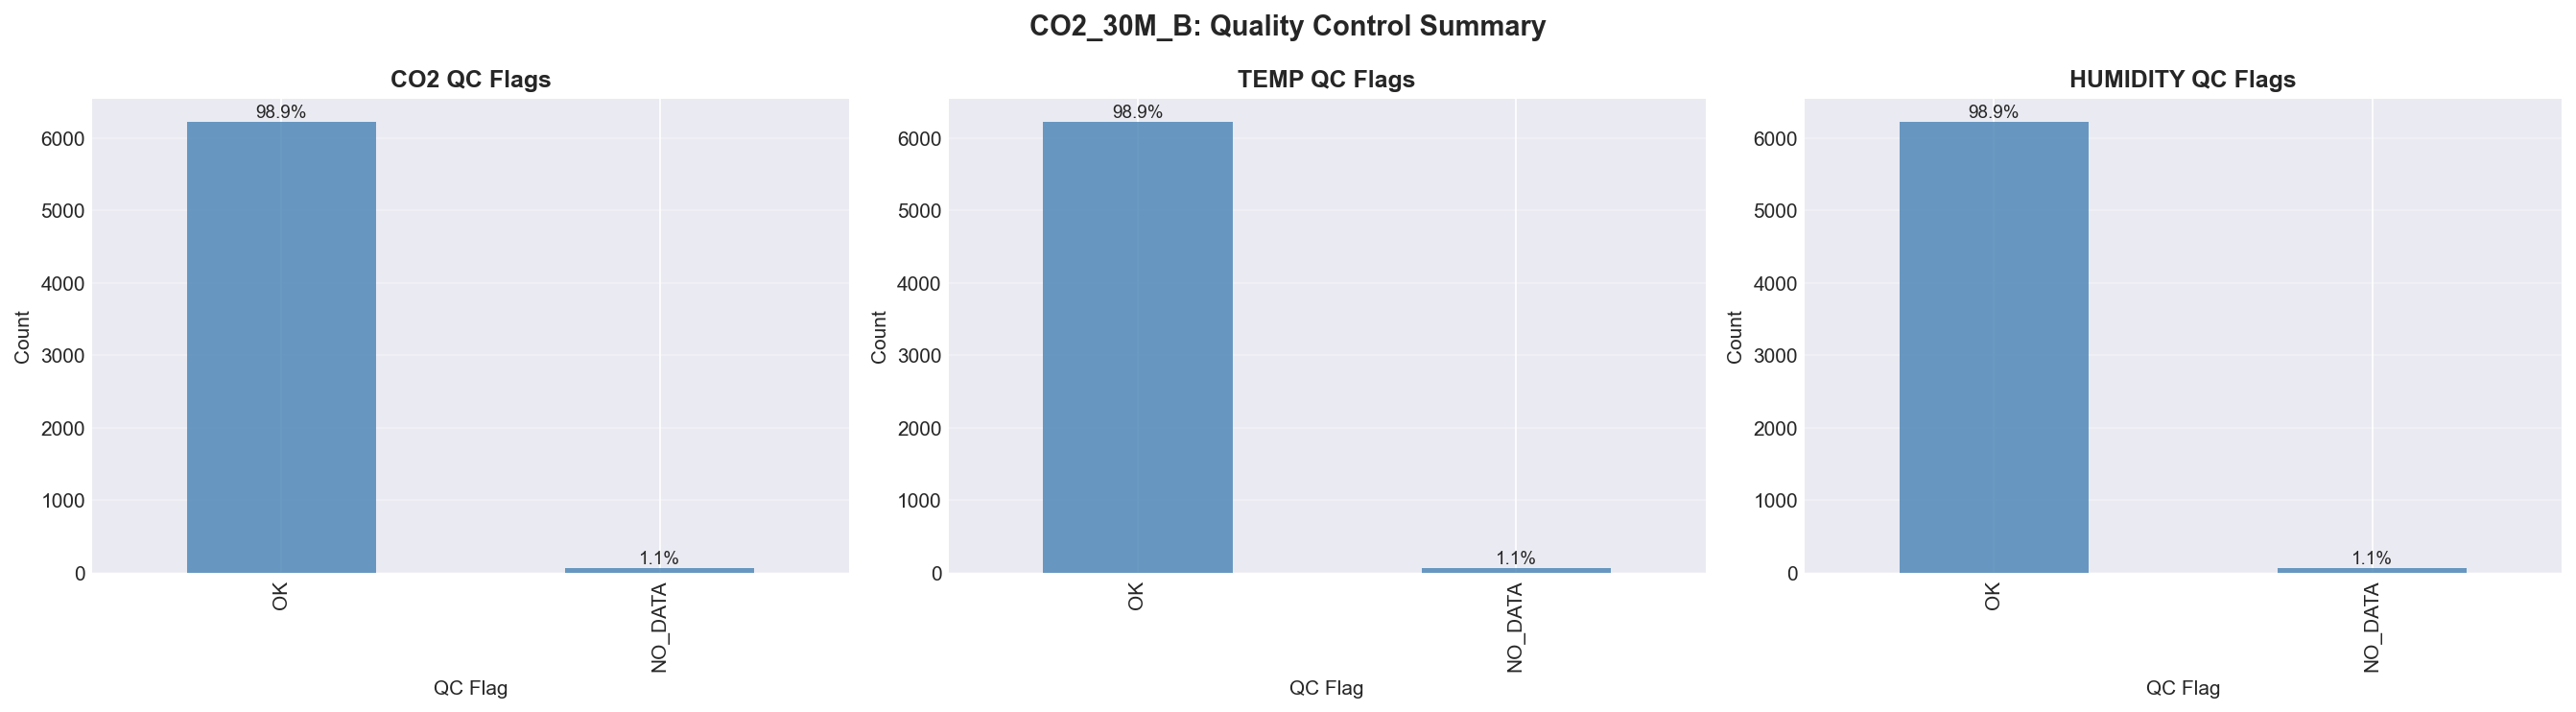

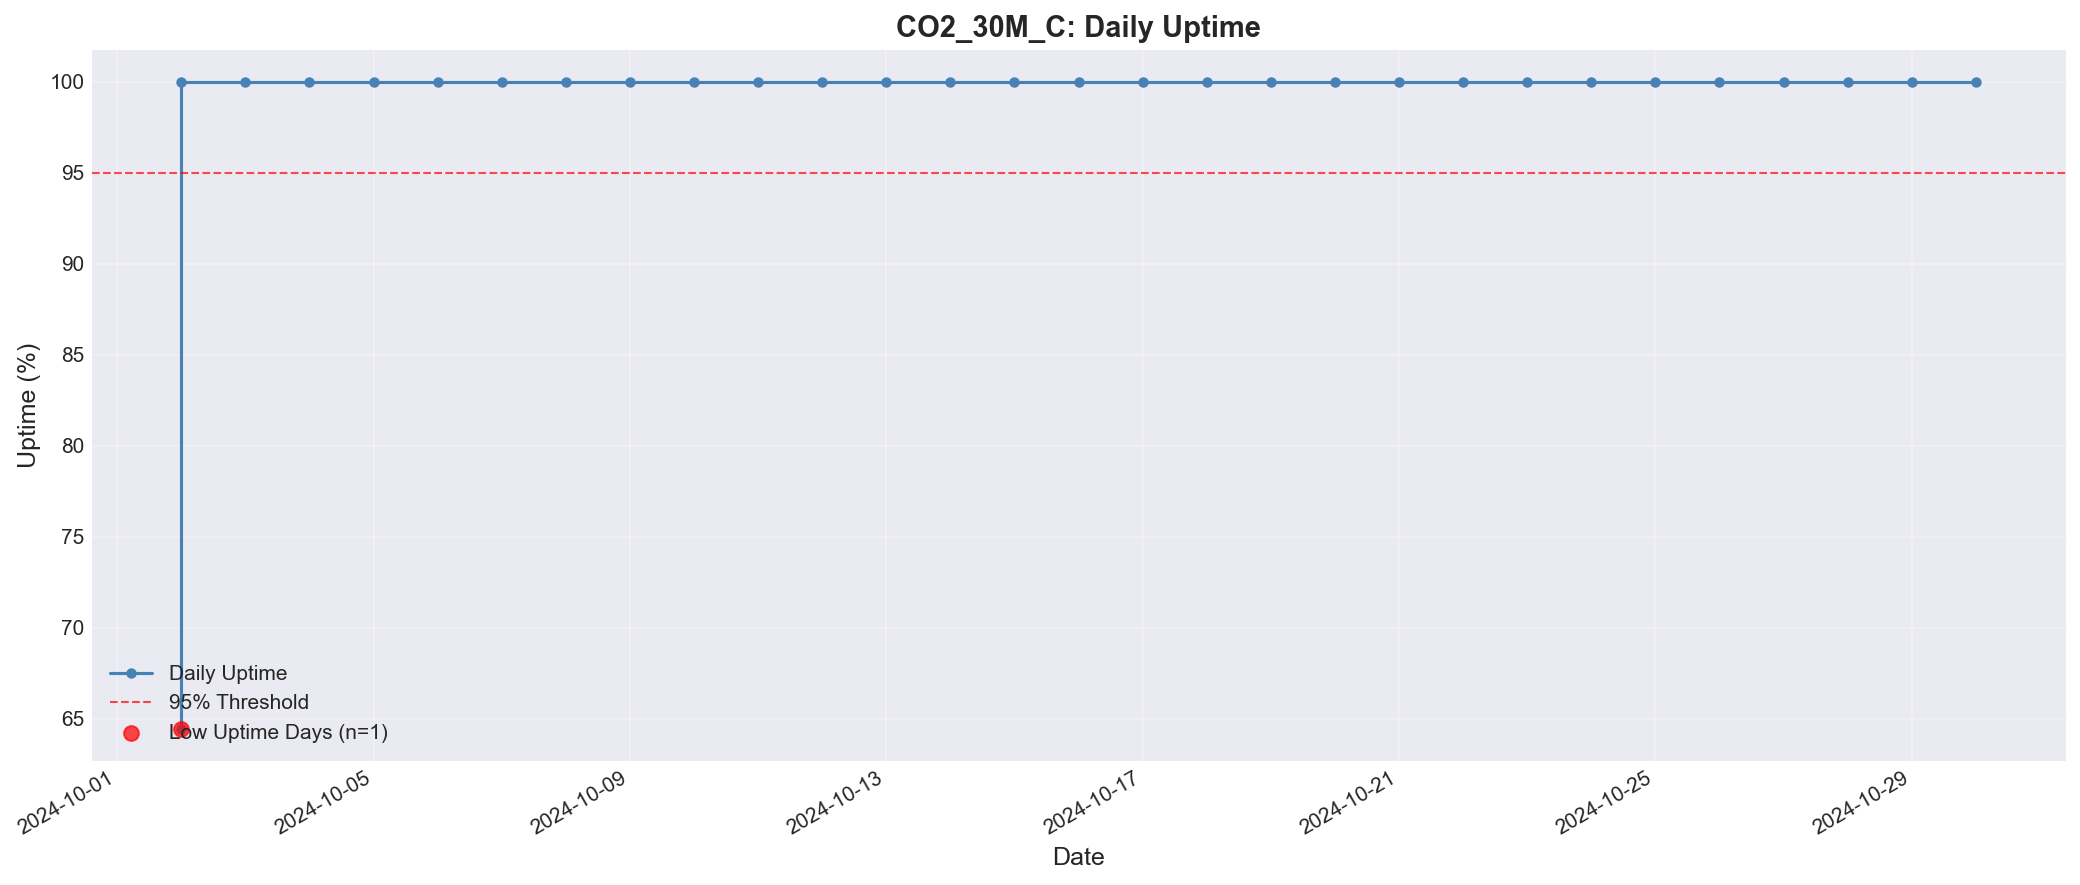

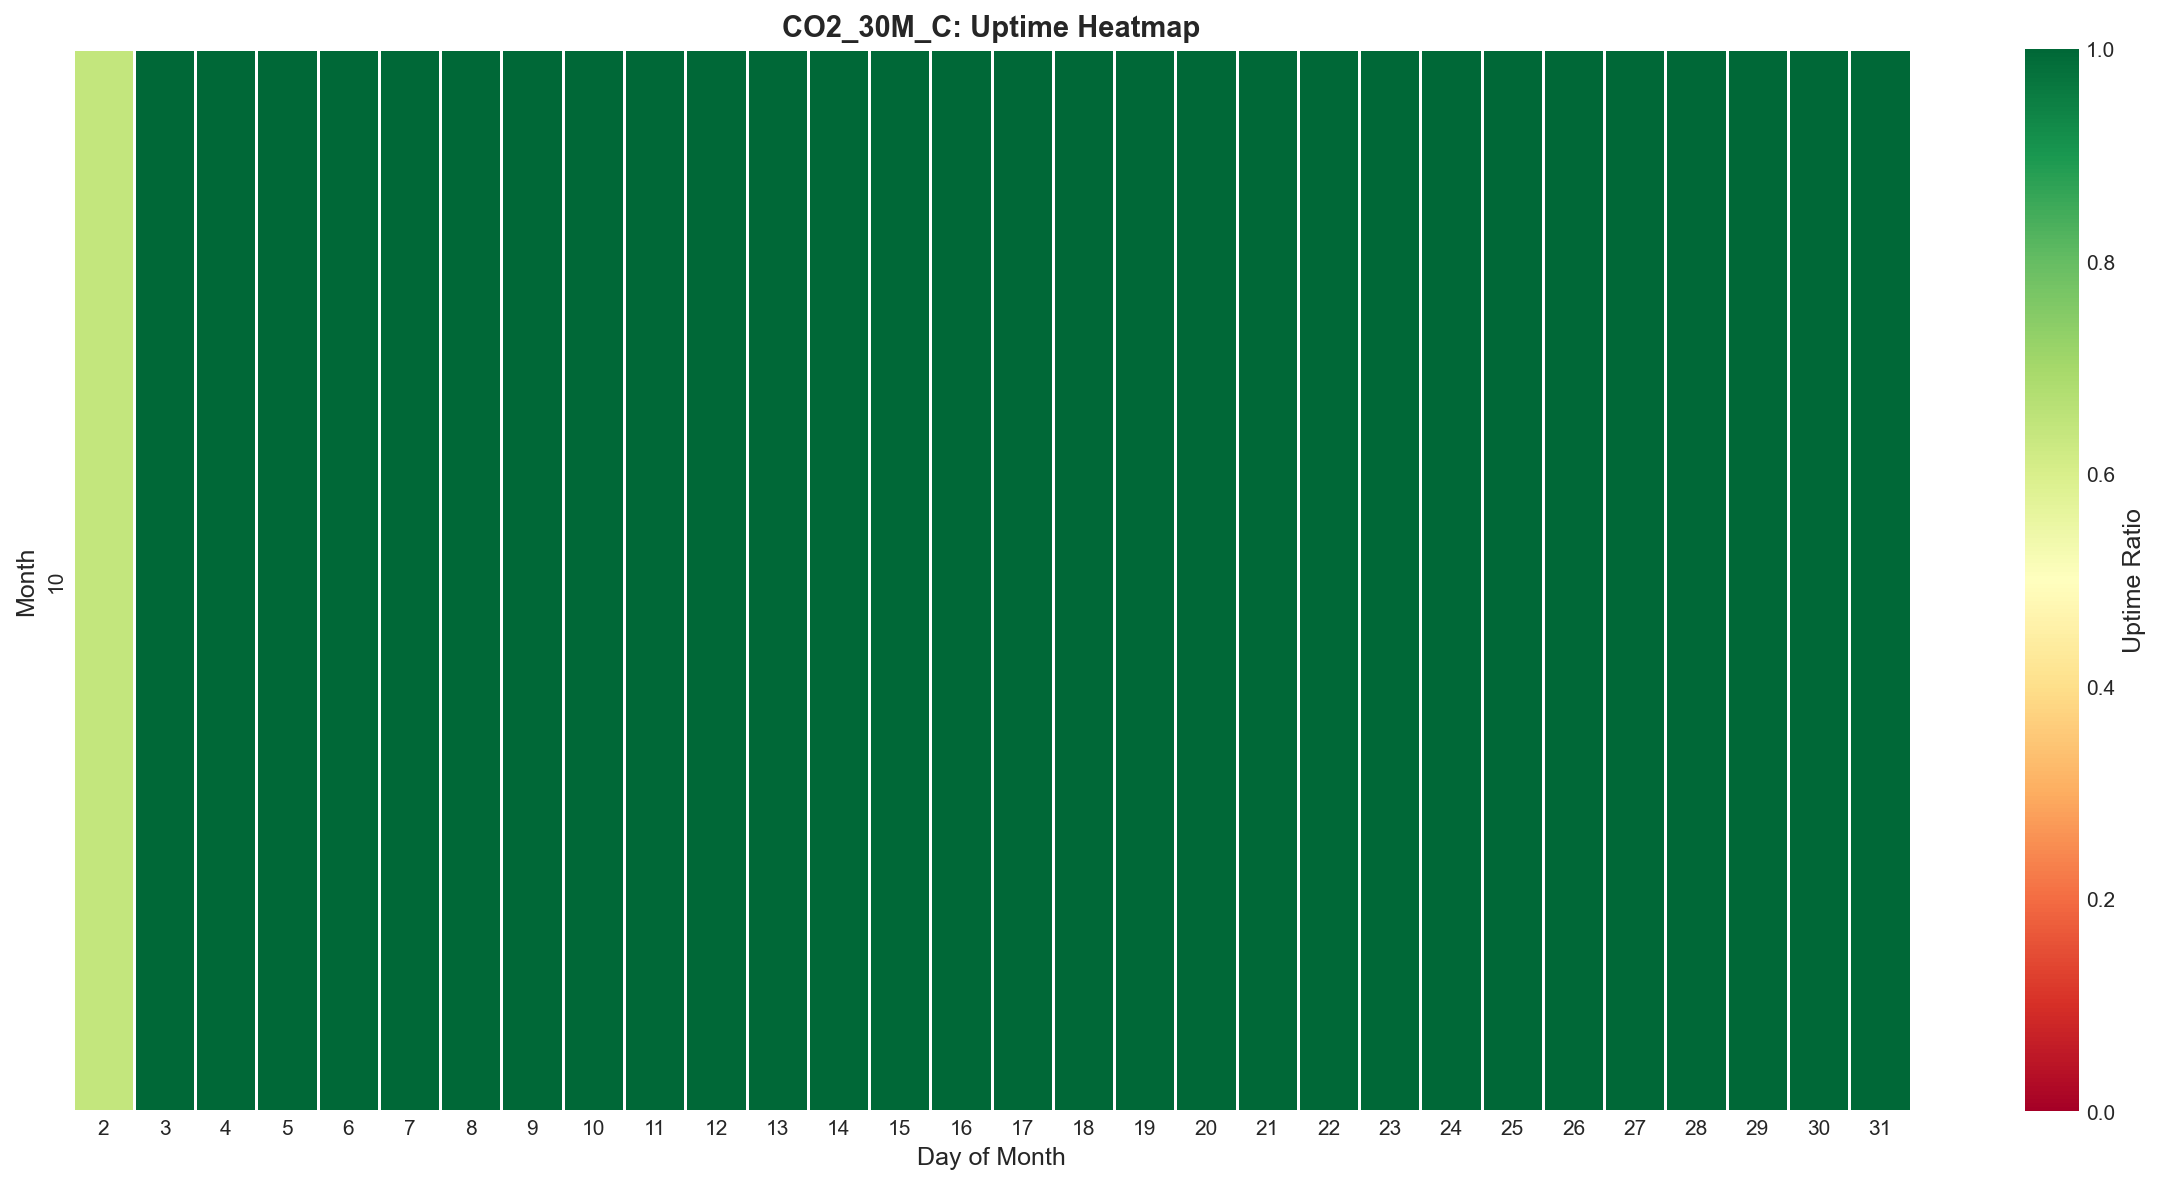

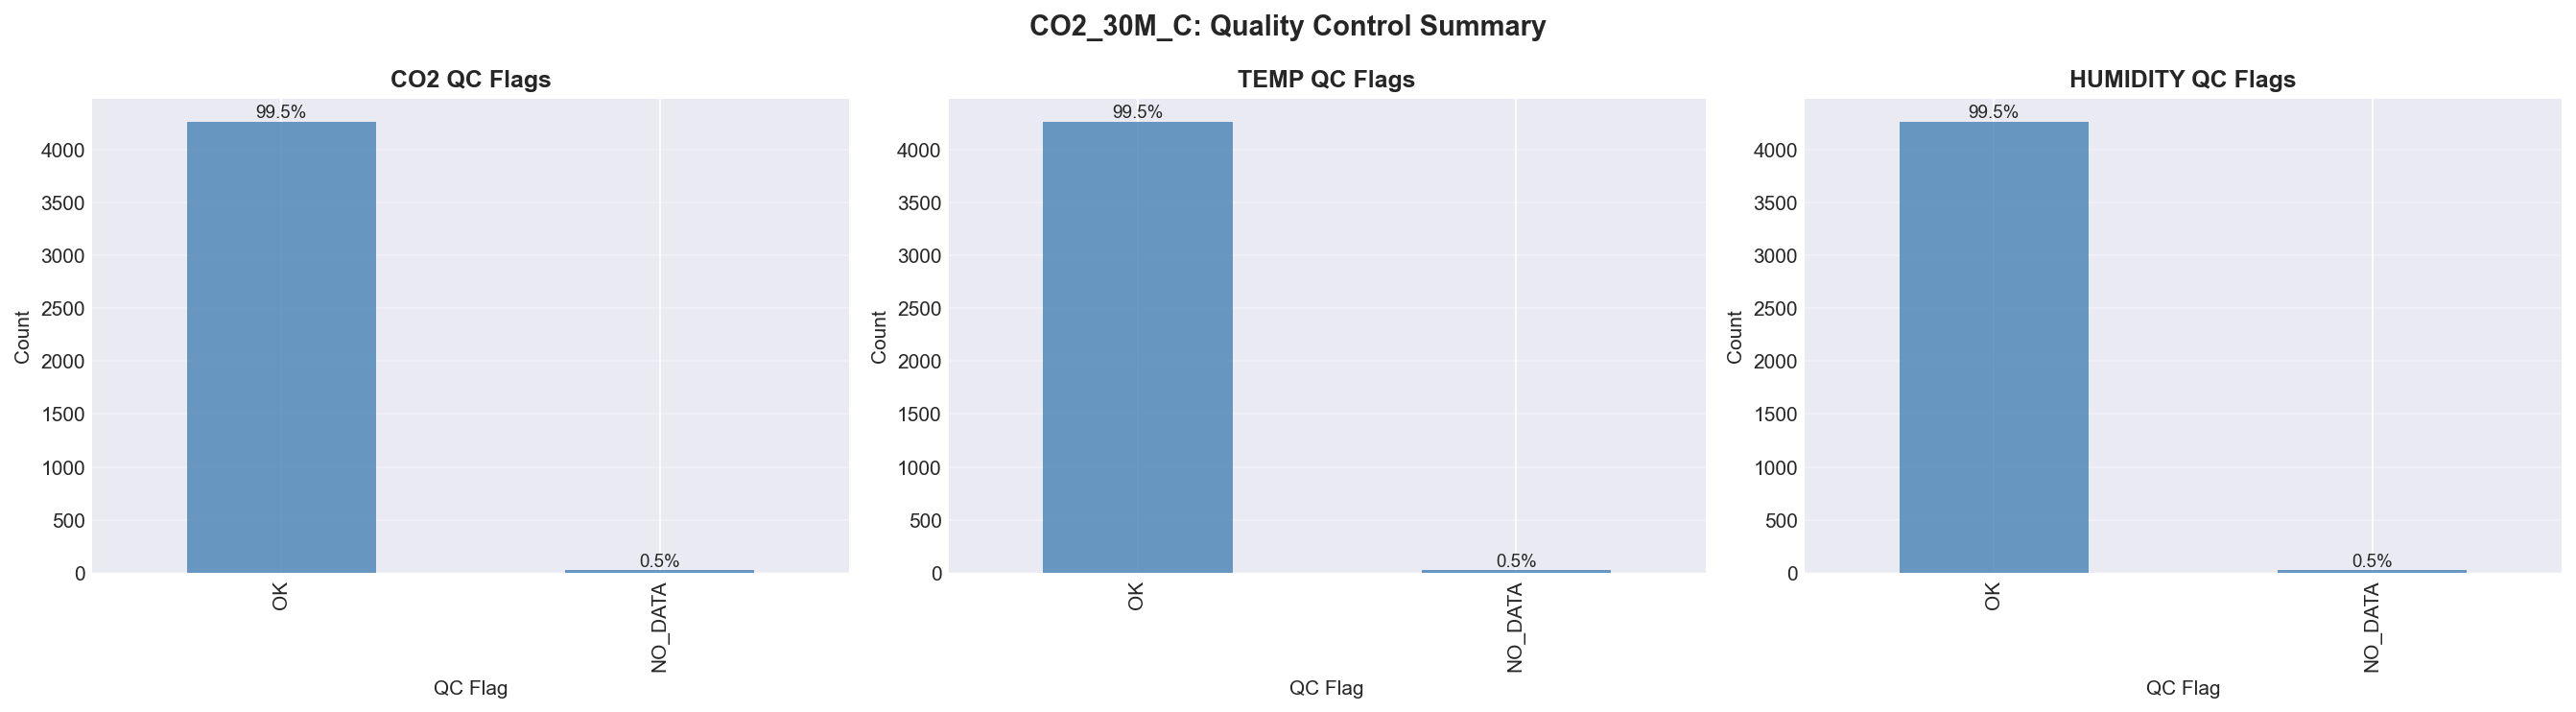

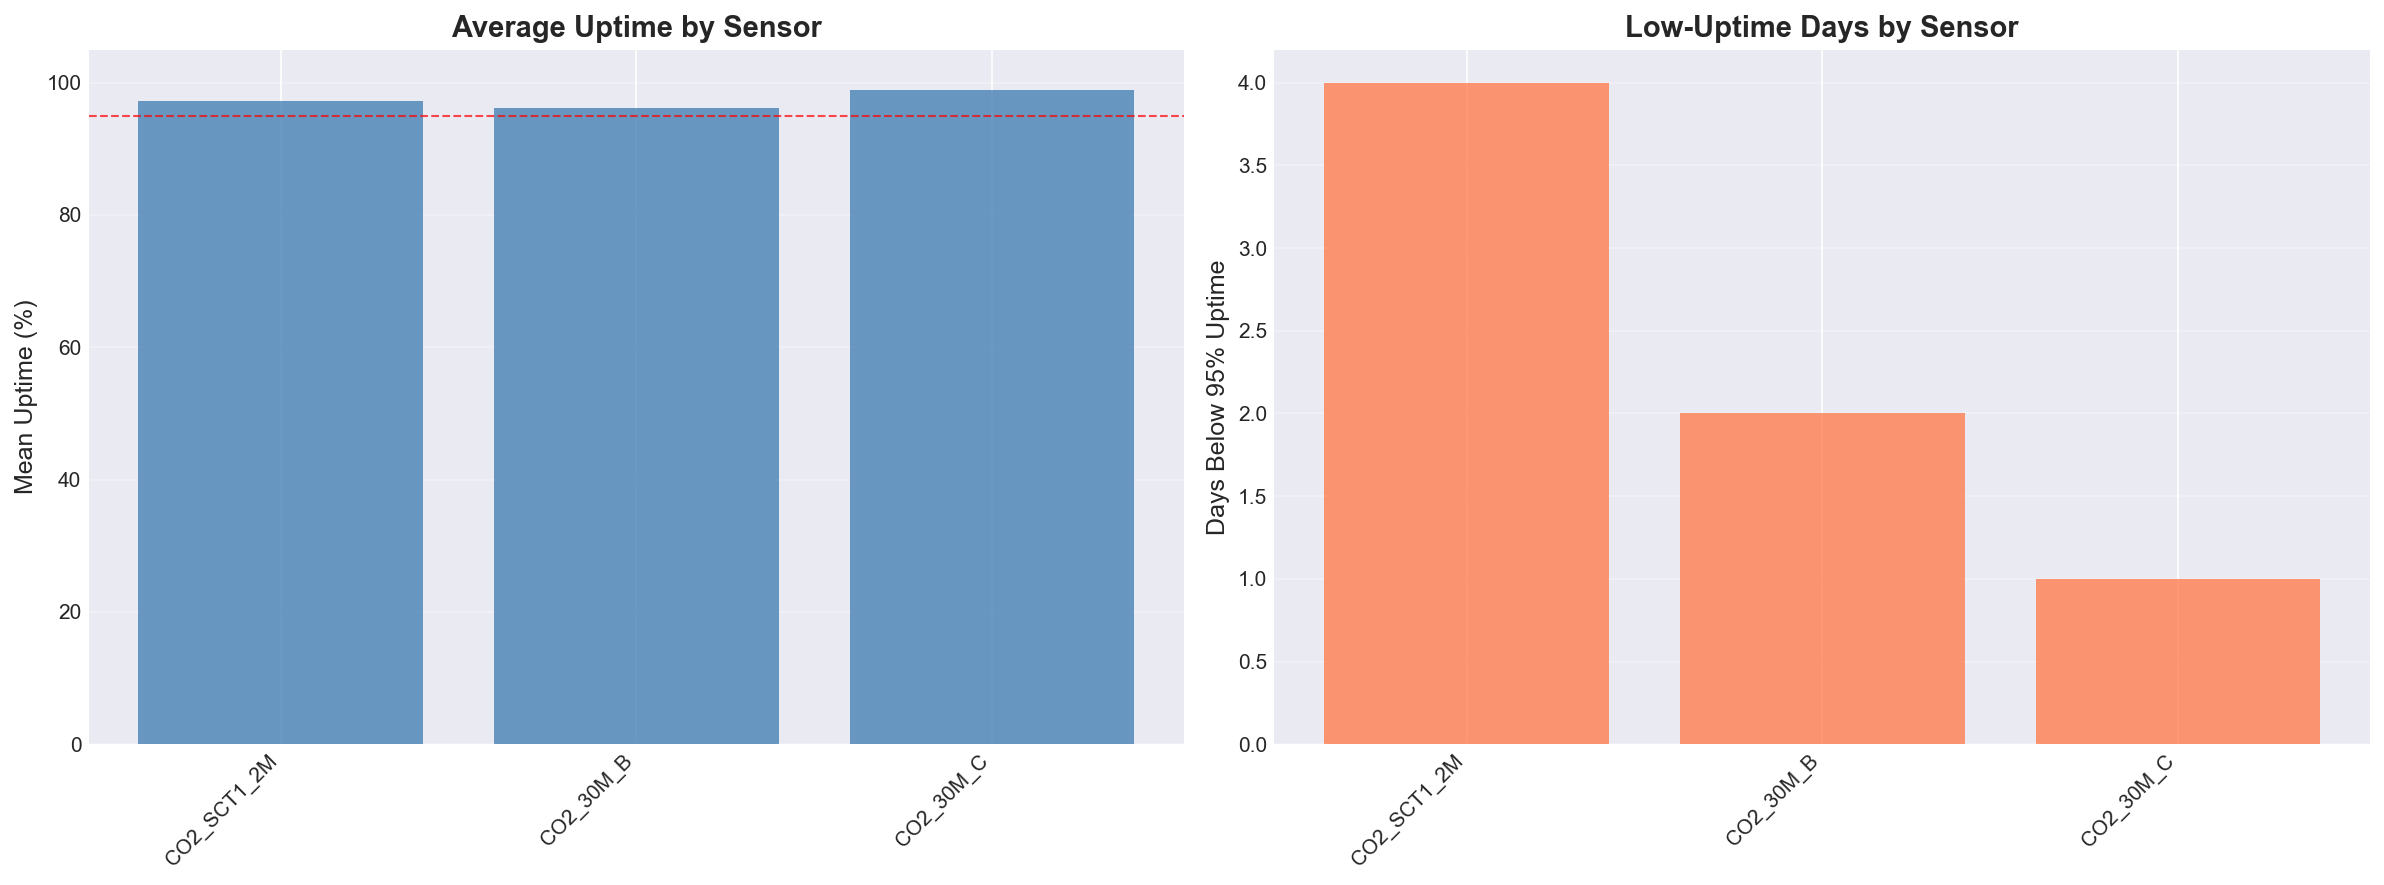

/home/mbz/Documents/PhD/SCD41_DATA/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


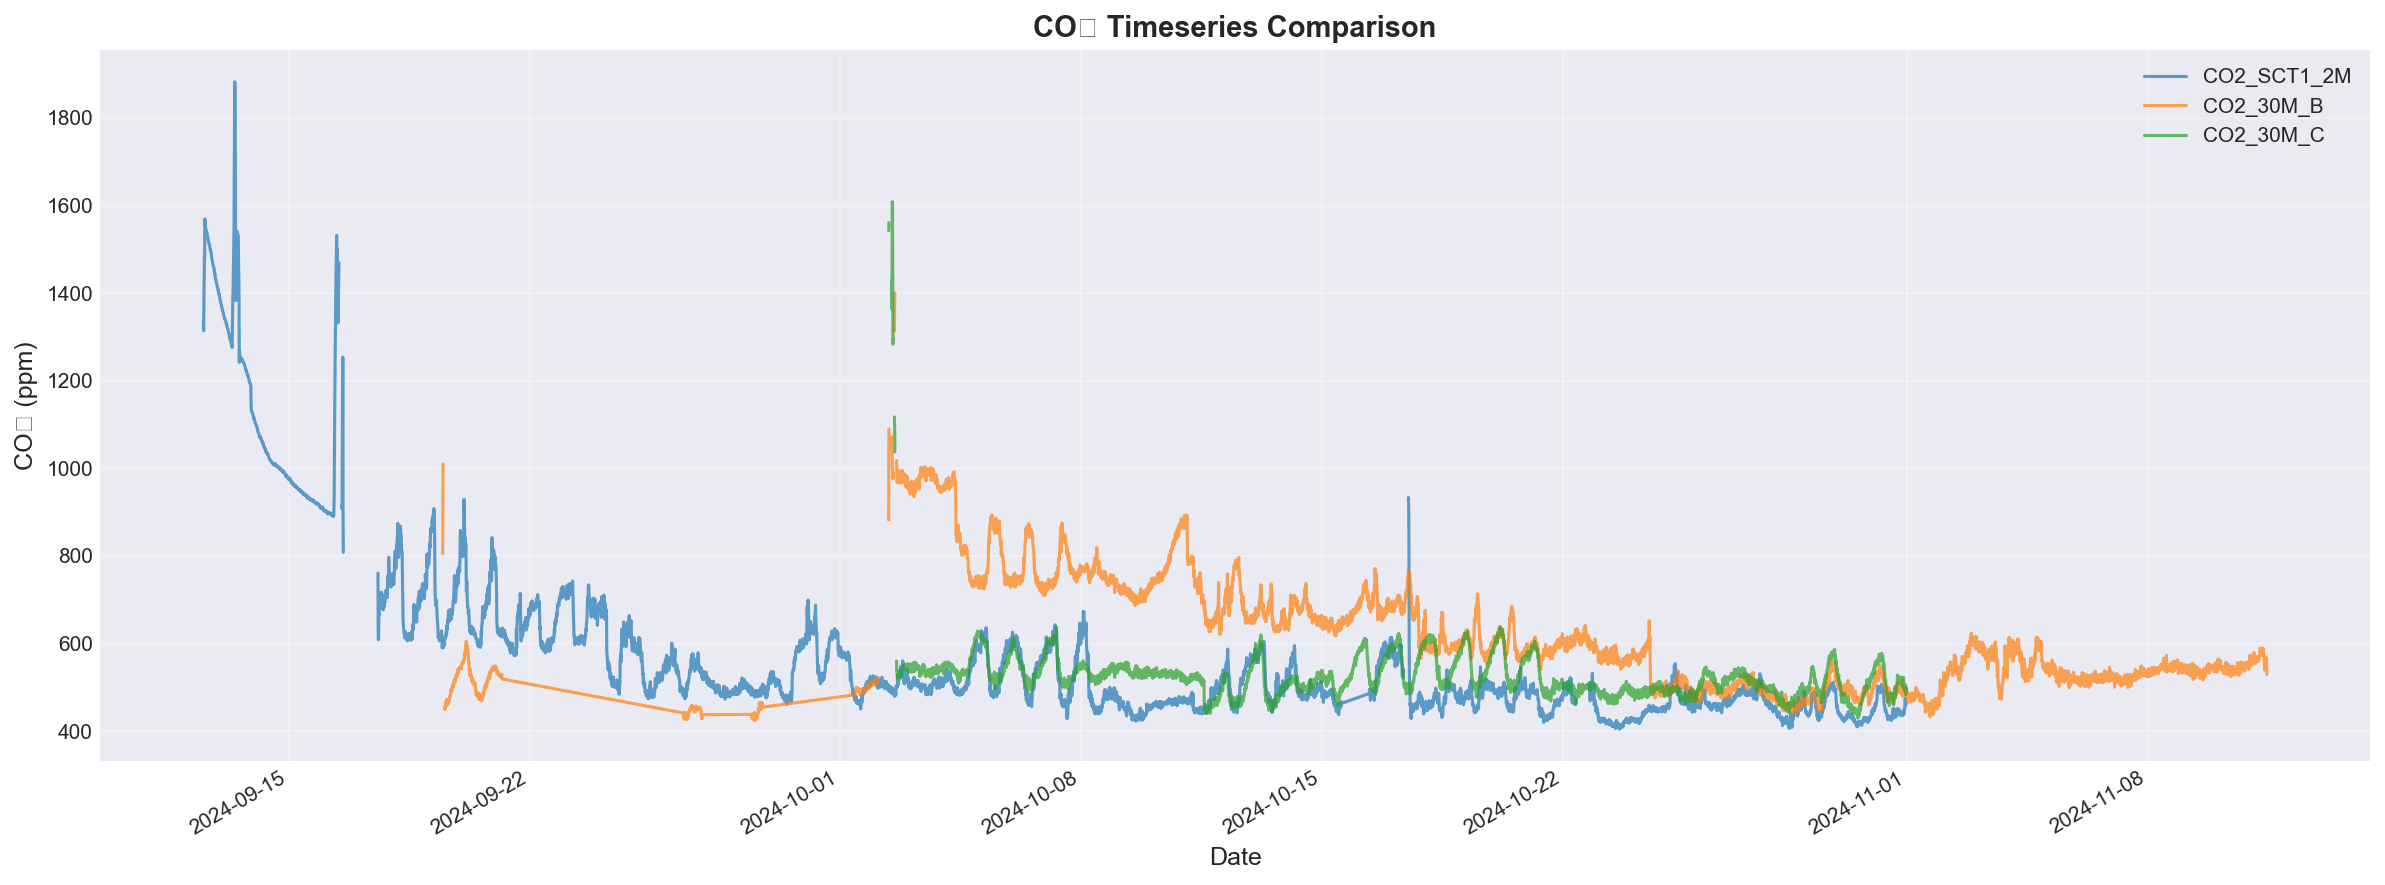

In [11]:
from src.visualization import generate_all_plots

# Generate all standard plots
generate_all_plots(config)

In [ ]:
from src.merger import merge_all_sensors

merged = merge_all_sensors(
    individual_dir=config.output_dir,
    sensor_names=[s.name for s in config.sensors]
)

print(f"Merged dataset shape: {merged.shape}")
print(f"Date range: {merged.index.min()} to {merged.index.max()}")
print(f"\nColumns: {list(merged.columns)}")